From the ACF and the PACF plots, the p, q and d values are:
p(2)
d(0) (if differencing)
q(2)

/Users/visjostr/school/parking-prediction/.venv/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


SARIMA MAE: 146.47174765243955, RMSE: 253.1492268473546


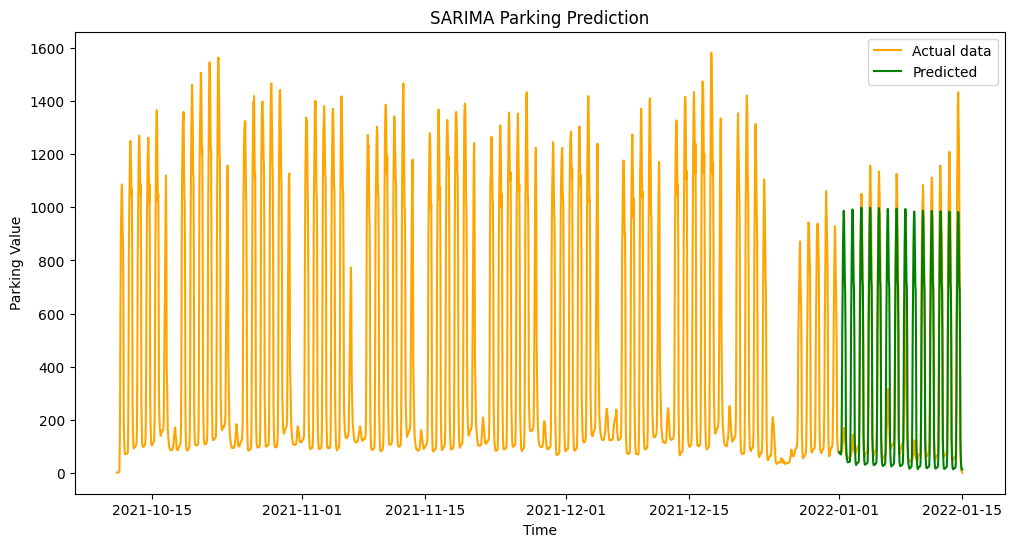

In [13]:
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.statespace.sarimax import SARIMAX
from datetime import datetime
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.preprocessing import StandardScaler
import numpy as np

# Set random seed for reproducibility
np.random.seed(42)

# Load and preprocess the dataset
def load_and_preprocess_data(filepath):
    df = pd.read_csv(filepath, delimiter=',')
    df['Time'] = pd.to_datetime(df['Time'])
    df.set_index('Time', inplace=True)
    df.sort_index(inplace=True)
    df_hourly = df.resample('h').mean()
    df_hourly['day_of_year'] = df_hourly.index.dayofyear
    df_hourly['weekday'] = df_hourly.index.dayofweek
    df_hourly['hour'] = df_hourly.index.hour
    df_hourly['is_holiday'] = df_hourly['is_holiday'].astype(int)
    df_hourly['is_sunday'] = (df_hourly.index.dayofweek == 6).astype(int)
    df_hourly['holiday_sunday'] = (df_hourly['is_holiday'] & df_hourly['is_sunday']).astype(int)
    
    # Standardize exogenous features
    scaler = StandardScaler()
    exog_features = df_hourly[['day_of_year', 'weekday', 'hour', 'is_holiday', 'is_sunday', 'holiday_sunday']]
    df_hourly[exog_features.columns] = scaler.fit_transform(exog_features)
    
    return df_hourly

# Split data into training and test sets
def split_data(df, end_date):
    train_data = df[df.index < end_date]
    test_data = df[df.index >= end_date]
    train_data.index = pd.DatetimeIndex(train_data.index.values, freq='h')
    return train_data, test_data

# Fit the SARIMA model
def fit_sarima_model(train_data, exogenous_features, order, seasonal_order):
    model = SARIMAX(train_data['Parkings'], 
                    order=order, 
                    seasonal_order=seasonal_order,
                    exog=train_data[exogenous_features],
                    enforce_stationarity=False,
                    enforce_invertibility=False)
    return model.fit(disp=False)

# Predict using the fitted model
def make_predictions(model, test_data, exogenous_features):
    predictions = model.predict(start=test_data.index[0], end=test_data.index[-1], exog=test_data[exogenous_features], dynamic=True)
    return predictions

# Calculate error metrics
def calculate_metrics(actual, predicted):
    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    return mae, rmse

# Plot the results
def plot_results(train_data, test_data, predictions):
    plt.figure(figsize=(12, 6))
    plt.plot(train_data.index, train_data['Parkings'], label='Actual data', color='orange')
    plt.plot(test_data.index, test_data['Parkings'], color='orange')
    plt.plot(test_data.index, predictions, label='Predicted', color='green')
    plt.xlabel('Time')
    plt.ylabel('Parking Value')
    plt.title('SARIMA Parking Prediction')
    plt.legend()
    plt.show()

# Main script
if __name__ == "__main__":
    filepath = '../preprocess/parking_time_series_with_features_1_hour.csv'
    df_hourly = load_and_preprocess_data(filepath)
    end_date = datetime(2022, 1, 1)
    train_data, test_data = split_data(df_hourly, end_date)
    exogenous_features = ["day_of_year", "weekday", "hour", "is_holiday", "is_sunday", "holiday_sunday"]
    sarima_order = (2, 1, 2)
    seasonal_order = (1, 1, 1, 24)
    sarima_model = fit_sarima_model(train_data, exogenous_features, sarima_order, seasonal_order)
    predictions = make_predictions(sarima_model, test_data, exogenous_features)
    mae, rmse = calculate_metrics(test_data['Parkings'], predictions)
    print(f'SARIMA MAE: {mae}, RMSE: {rmse}')
    plot_results(train_data, test_data, predictions)

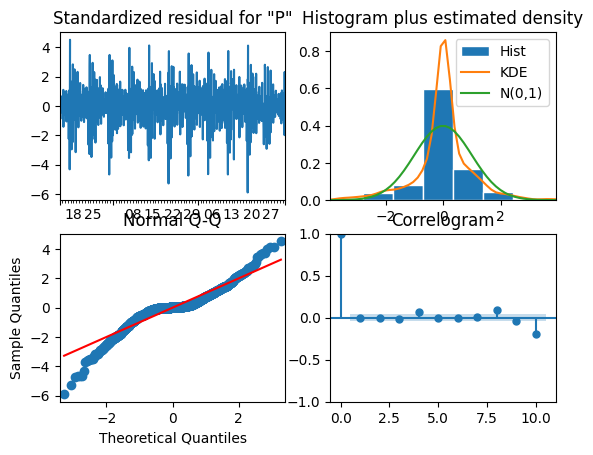

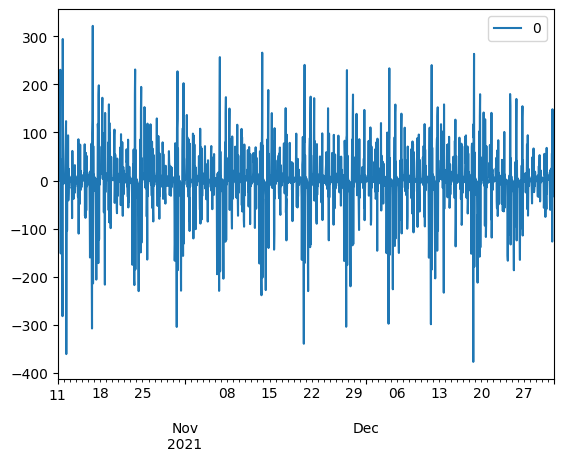

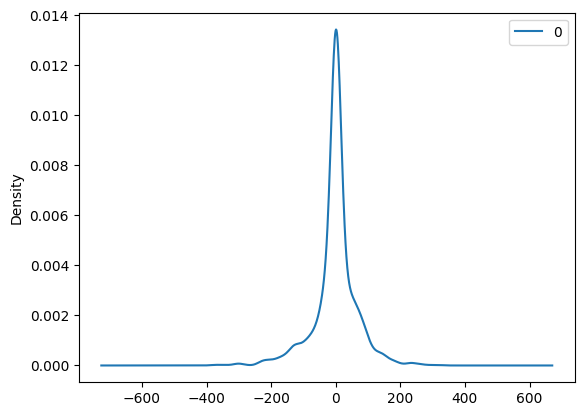

                 0
count  1968.000000
mean     -0.428180
std      66.110044
min    -376.748279
25%     -14.384396
50%       1.084646
75%      19.478023
max     321.296209


In [12]:
sarima_model.plot_diagnostics()
residuals = pd.DataFrame(sarima_model.resid)
residuals.plot()
residuals.plot(kind='kde')
plt.show()
print(residuals.describe())